# Assignment 01: Car Mileage Prediction with Regression

## Aim
Build a supervised regression workflow that estimates vehicle fuel mileage (MPG) from basic engineering specifications.

## Models Used
1. Linear Regression
2. Random Forest Regression

## Evaluation
The models are compared using MAE, RMSE and R² on a held-out test set. An Actual-versus-Predicted plot is also used to inspect the predictions visually.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
np.random.seed(17)

n = 520

engine_size = np.random.uniform(1.0, 5.0, n)

horsepower = (
    60
    + engine_size * 40
    + np.random.normal(0, 15, n)
)

weight = (
    900
    + engine_size * 350
    + np.random.normal(0, 100, n)
)

cylinders = np.clip(
    np.round(engine_size * 1.6),
    3,
    12
)

mpg = (
    45
    - engine_size * 4
    - weight * 0.005
    - horsepower * 0.03
    + np.random.normal(0, 1.5, n)
)

mpg = np.clip(mpg, 8, 45)

car_df = pd.DataFrame({
    "engine_size_L": engine_size,
    "horsepower": horsepower,
    "weight_kg": weight,
    "cylinders": cylinders,
    "mpg": mpg
})

car_df.head()

,engine_size_L,horsepower,weight_kg,cylinders,mpg
0,2.178660,138.344704,1678.474380,3.0,24.089221
1,3.122347,194.020638,2001.735057,5.0,16.437928
2,1.766083,117.540021,1430.868819,3.0,26.407909
3,1.271601,97.619414,1415.360441,3.0,33.120516
4,4.147942,245.251463,2446.249018,7.0,8.034815


In [3]:
print("Dataset Shape:", car_df.shape)

print("\nDataset Information:")
print(car_df.info())

print("\nStatistical Summary:")
display(car_df.describe())

Dataset Shape: (520, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   engine_size_L  520 non-null    float64
 1   horsepower     520 non-null    float64
 2   weight_kg      520 non-null    float64
 3   cylinders      520 non-null    float64
 4   mpg            520 non-null    float64
dtypes: float64(5)
memory usage: 20.4 KB
None

Statistical Summary:


,engine_size_L,horsepower,weight_kg,cylinders,mpg
count,520.000000,520.000000,520.000000,520.000000,520.000000
mean,3.032877,181.844909,1962.806424,4.998077,18.064811
std,1.150879,48.027437,420.715050,1.680099,7.669434
min,1.008820,78.173605,1064.525691,3.000000,8.000000
25%,2.053095,143.113088,1597.654669,3.000000,10.671473
50%,3.060772,184.231170,1979.669316,5.000000,17.540256
75%,4.048009,221.620171,2337.047572,6.000000,24.064094
max,4.999134,310.154047,2979.252861,8.000000,33.120516


In [4]:
X = car_df.drop(columns=["mpg"])
y = car_df["mpg"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,engine_size_L,horsepower,weight_kg,cylinders
0,2.178660,138.344704,1678.474380,3.0
1,3.122347,194.020638,2001.735057,5.0
2,1.766083,117.540021,1430.868819,3.0
3,1.271601,97.619414,1415.360441,3.0
4,4.147942,245.251463,2446.249018,7.0



Target:


,mpg
0,24.089221
1,16.437928
2,26.407909
3,33.120516
4,8.034815


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=17
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 416
Testing samples: 104


In [6]:
lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

lr_preds = lr.predict(X_test)

In [7]:
rf = RandomForestRegressor(
    n_estimators=220,
    random_state=17
)

rf.fit(
    X_train,
    y_train
)

rf_preds = rf.predict(X_test)

In [8]:
results = []

for name, predictions in [
    ("Linear Regression", lr_preds),
    ("Random Forest", rf_preds)
]:

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = mean_squared_error(
        y_test,
        predictions
    ) ** 0.5

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(3)
)

,Model,MAE,RMSE,R2
0,Linear Regression,1.032,1.231,0.976
1,Random Forest,1.027,1.364,0.970


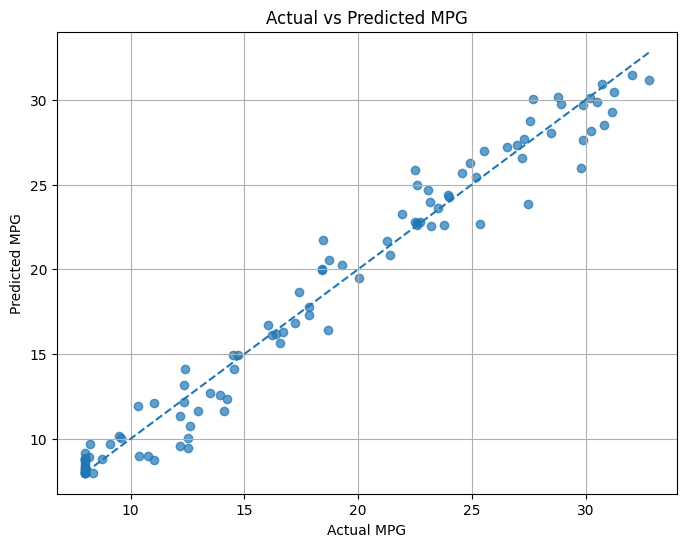

In [9]:
best_predictions = rf_preds

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")

plt.grid(True)
plt.show()

## Result / Conclusion

The regression workflow was completed using simulated vehicle specifications as input variables and MPG as the target.

Both Linear Regression and Random Forest Regression were trained on the same train-test split. MAE, RMSE and R² were used to compare the predictions, while the final scatter plot provides a visual check of how closely the predicted MPG follows the actual values.